# 02 — Baseline CNN

The baseline is a scratch three-block convolutional network with no pretrained weights, no augmentation, no class weights, and no label smoothing. It is trained for 20 epochs on the fixed 25% subset, with validation macro-F1 used for checkpoint selection.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\DAR\Desktop\Pneumonia_classification\p06-pneumonia-limited-data


In [2]:
import yaml
print(yaml.safe_dump({
    "model": {"name": "baseline_cnn", "pretrained": False, "input_channels": 3},
    "training": {"epochs": 20, "batch_size": 16, "optimizer": "adam",
                 "lr": 1e-3, "augment": False, "class_weights_from_subset": False,
                 "label_smoothing": 0.0},
}, sort_keys=False))

model:
  name: baseline_cnn
  pretrained: false
  input_channels: 3
training:
  epochs: 20
  batch_size: 16
  optimizer: adam
  lr: 0.001
  augment: false
  class_weights_from_subset: false
  label_smoothing: 0.0



To retrain from a shell (about 22–25 minutes per seed on the CPU host):

```powershell
python -m src.train --config configs/baseline.yaml --seed 42
python -m src.evaluate --checkpoint checkpoints/baseline_seed42.pt --splits val test
```

Existing results are loaded below; no training is started by this notebook.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.read_csv("results/baseline/seed42/history.csv")
hist[["epoch", "train_loss", "val_loss", "val_accuracy", "val_macro_f1"]].tail(10)

Out[0]: 
    epoch  train_loss  val_loss  val_accuracy  val_macro_f1
10     11    0.833106  0.828707      0.635251      0.471972
11     12    0.824500  0.783670      0.647491      0.478972
12     13    0.800943  0.779294      0.658507      0.493946
13     14    0.807114  0.752320      0.667075      0.512706
14     15    0.767191  0.782247      0.638923      0.483386
15     16    0.791116  0.848889      0.619339      0.583577
16     17    0.773361  0.711907      0.671971      0.506242
17     18    0.764427  0.731073      0.671971      0.506554
18     19    0.754298  0.723071      0.649939      0.484104
19     20    0.742529  0.688334      0.700122      0.599431


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
10,11,0.833106,0.828707,0.635251,0.471972
11,12,0.824500,0.783670,0.647491,0.478972
12,13,0.800943,0.779294,0.658507,0.493946
13,14,0.807114,0.752320,0.667075,0.512706
14,15,0.767191,0.782247,0.638923,0.483386
15,16,0.791116,0.848889,0.619339,0.583577
16,17,0.773361,0.711907,0.671971,0.506242
17,18,0.764427,0.731073,0.671971,0.506554
18,19,0.754298,0.723071,0.649939,0.484104
19,20,0.742529,0.688334,0.700122,0.599431


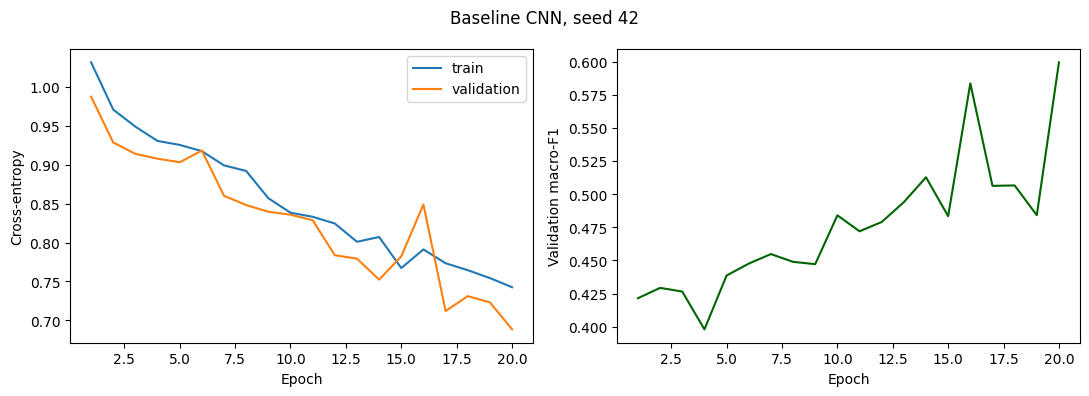

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train")
axes[0].plot(hist.epoch, hist.val_loss, label="validation")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(hist.epoch, hist.val_macro_f1, color="darkgreen")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation macro-F1")
fig.suptitle("Baseline CNN, seed 42")
fig.tight_layout()
plt.show()

In [5]:
import json
for seed in (42, 43, 44):
    m = json.load(open(f"results/baseline/seed{seed}/metrics_test.json"))
    print(seed, {k: round(m[k], 4) for k in ("accuracy", "balanced_accuracy", "macro_f1", "macro_auroc", "ece")})

42 {'accuracy': 0.6074, 'balanced_accuracy': 0.5488, 'macro_f1': 0.5296, 'macro_auroc': 0.8724, 'ece': 0.1146}
43 {'accuracy': 0.6362, 'balanced_accuracy': 0.5657, 'macro_f1': 0.5299, 'macro_auroc': 0.8847, 'ece': 0.1116}
44 {'accuracy': 0.7131, 'balanced_accuracy': 0.7043, 'macro_f1': 0.6968, 'macro_auroc': 0.8923, 'ece': 0.1087}


Test macro-F1: 0.5296, 0.5299, 0.6968 for seeds 42, 43, 44. The baseline's main failure is VIRUS recall; it often predicts BACTERIA instead.